# Global Market Entry Intelligence — reproducible walkthrough

**Research portfolio: Jinlei Cao**  
**Important:** This notebook initially uses an **entirely synthetic** country dataset to teach the method. Do **not** report these country values or rankings as facts. For empirical work, obtain the actual World Bank data using the CLI and check the observation years.

This notebook explains how the five criteria are constructed, how the weighting method and TOPSIS differ, and how changes in assumed preferences can alter rankings.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from marketintel.config import INDICATORS, WEIGHTS
from marketintel.data import generate_synthetic_panel
from marketintel.scoring import build_matrix, normalize_matrix, rank_countries, weight_sensitivity

print("Research mode: SYNTHETIC — NOT WORLD BANK DATA")

Research mode: SYNTHETIC — NOT WORLD BANK DATA


## 1. Research design and indicator definitions

- Market: log GDP and GDP growth.
- Governance: regulatory-quality perception estimate.
- Operations: historical, **survey-based** Logistics Performance Index.
- Digital: internet usage.

The initial candidate country names are hypothetical labels attached to invented values. The real research requires the country selection and indicator availability to be checked independently.

In [2]:
pd.DataFrame([
    {"code": ind.code, "dimension": ind.group, "definition": ind.label,
     "weight": WEIGHTS[ind.code], "source_id": ind.source,
     "max_age": ind.max_age}
    for ind in INDICATORS
])

,code,dimension,definition,weight,source_id,max_age
0,NY.GDP.MKTP.CD,Market,Market size: GDP (current US$),0.23,2,4
1,NY.GDP.MKTP.KD.ZG,Market,Real GDP growth (%),0.12,2,4
2,RQ.EST,Governance,Regulatory quality (WGI estimate),0.23,3,4
3,LP.LPI.OVRL.XQ,Operations,Logistics Performance Index (survey),0.25,2,5
4,IT.NET.USER.ZS,Digital,Internet users (% of population),0.17,2,4


## 2. Generate the deterministic offline test panel

No World Bank observations have been fetched here.

In [3]:
panel = generate_synthetic_panel(seed=2027)
panel.head(10)

,iso3,country,indicator,indicator_label,year,age_years,value,status,source,source_id
0,IDN,Indonesia,NY.GDP.MKTP.CD,Market size: GDP (current US$),2023,2,1.485956e+10,SYNTHETIC,SYNTHETIC / NOT WORLD BANK DATA,-1
1,IDN,Indonesia,NY.GDP.MKTP.KD.ZG,Real GDP growth (%),2025,0,2.110855e+00,SYNTHETIC,SYNTHETIC / NOT WORLD BANK DATA,-1
2,IDN,Indonesia,RQ.EST,Regulatory quality (WGI estimate),2023,2,-6.668605e-01,SYNTHETIC,SYNTHETIC / NOT WORLD BANK DATA,-1
3,IDN,Indonesia,LP.LPI.OVRL.XQ,Logistics Performance Index (survey),2023,2,2.563405e+00,SYNTHETIC,SYNTHETIC / NOT WORLD BANK DATA,-1
4,IDN,Indonesia,IT.NET.USER.ZS,Internet users (% of population),2025,0,3.395747e+01,SYNTHETIC,SYNTHETIC / NOT WORLD BANK DATA,-1
5,VNM,Viet Nam,NY.GDP.MKTP.CD,Market size: GDP (current US$),2023,2,1.386938e+09,SYNTHETIC,SYNTHETIC / NOT WORLD BANK DATA,-1
6,VNM,Viet Nam,NY.GDP.MKTP.KD.ZG,Real GDP growth (%),2024,1,2.702314e-01,SYNTHETIC,SYNTHETIC / NOT WORLD BANK DATA,-1
7,VNM,Viet Nam,RQ.EST,Regulatory quality (WGI estimate),2023,2,7.046082e-02,SYNTHETIC,SYNTHETIC / NOT WORLD BANK DATA,-1
8,VNM,Viet Nam,LP.LPI.OVRL.XQ,Logistics Performance Index (survey),2023,2,3.323499e+00,SYNTHETIC,SYNTHETIC / NOT WORLD BANK DATA,-1
9,VNM,Viet Nam,IT.NET.USER.ZS,Internet users (% of population),2023,2,5.728742e+01,SYNTHETIC,SYNTHETIC / NOT WORLD BANK DATA,-1


## 3. Handle completeness and rescale values

The baseline uses countries with complete (synthetic) indicators. GDP is log-transformed. Indicators are mapped to relative scores 0–100 within the selected candidate set; 50 indicates a neutral value in a constant series.

In [4]:
matrix, missingness = build_matrix(panel, missing_policy="exclude")
score_matrix = normalize_matrix(matrix)
print("Eligible markets:", len(matrix))
print("Countries with missing indicators:", sum(missingness.missing_indicators > 0))
score_matrix.head()

Eligible markets: 18
Countries with missing indicators: 0


,NY.GDP.MKTP.CD,NY.GDP.MKTP.KD.ZG,RQ.EST,LP.LPI.OVRL.XQ,IT.NET.USER.ZS
iso3,,,,,
BGD,29.566340,28.147527,25.923812,25.578591,17.578639
EGY,29.634521,13.720391,30.139433,66.317606,100.000000
ETH,37.690614,46.837944,14.002474,29.121260,4.471803
GEO,100.000000,65.275235,29.171273,52.383589,72.866201
IDN,55.847421,39.435085,13.369227,33.241946,5.874771


## 4. Compare weighted sum and TOPSIS

The resulting rank is comparative, not a forecast of investment return. A high score does not imply that legal, operational or corporate entry requirements are satisfied.

In [5]:
metadata = panel[["iso3", "country"]].drop_duplicates()
ranking = rank_countries(score_matrix, metadata)
ranking.head(10)

,rank,iso3,country,weighted_sum,topsis_rank,topsis_closeness
0,1,PAK,Pakistan,82.883654,1,0.761538
1,2,TUR,Türkiye,73.227076,2,0.745296
2,3,MAR,Morocco,71.140962,3,0.669625
3,4,UZB,Uzbekistan,69.996394,4,0.669424
4,5,GEO,Georgia,63.025572,5,0.563647
5,6,KHM,Cambodia,49.828390,7,0.458143
6,7,EGY,Egypt,48.973858,6,0.496456
7,8,PHL,Philippines,46.229455,8,0.448391
8,9,ZAF,South Africa,39.586872,11,0.380700
9,10,KEN,Kenya,39.351564,12,0.366463


## 5. Preference-weight sensitivity

The following Dirichlet simulation changes **assumed criterion preferences** only. It does not simulate future economic performance or quantify measurement error.

In [6]:
robustness = weight_sensitivity(score_matrix, n_sim=1200, seed=42)
robustness.merge(metadata, on="iso3").sort_values("probability_rank_1", ascending=False).head(10)

,iso3,probability_rank_1,mean_rank,p10_score,p50_score,p90_score,country
0,PAK,0.999167,1.000833,78.744949,83.061507,87.150238,Pakistan
1,UZB,0.000833,3.643333,68.310103,69.943810,71.855942,Uzbekistan
2,TUR,0.000000,2.505833,69.883891,73.195688,76.504741,Türkiye
3,MAR,0.000000,2.914167,68.999504,71.087971,73.211974,Morocco
4,GEO,0.000000,4.935833,58.642066,62.784734,67.172668,Georgia
5,KHM,0.000000,6.583333,45.389231,49.653886,54.258382,Cambodia
6,EGY,0.000000,6.981667,44.022564,48.930966,53.960651,Egypt
7,PHL,0.000000,7.760833,41.940651,46.237611,50.522889,Philippines
8,ZAF,0.000000,9.675833,37.380745,39.578148,41.797167,South Africa
9,KEN,0.000000,10.004167,32.717127,39.367914,46.087609,Kenya


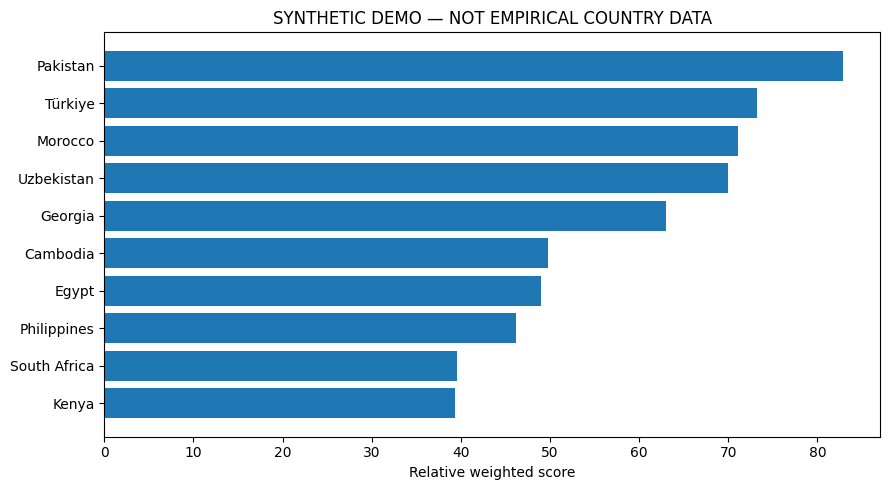

In [7]:
plot_table = ranking.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_table.country, plot_table.weighted_sum)
ax.set(xlabel="Relative weighted score", title="SYNTHETIC DEMO — NOT EMPIRICAL COUNTRY DATA")
plt.tight_layout()
plt.show()

## 6. Real-world study: separately run the CLI

From a local terminal in the repository root, with internet access:

```bash
marketintel fetch
marketintel analyze --input data/processed/world_bank_market_panel.csv --output reports/latest
streamlit run app/streamlit_app.py
```

Then inspect `reports/latest/source_observations.csv`, `data_completeness.csv`, and `analysis_manifest.json`. Do not silently treat differently dated indicators as a single-year panel. Never combine the 2023 **survey LPI** and the newer LPI 2.0 tracking-based indicators as though they have the same metric definition.

**Researcher review:** Re-run and understand the computations, compare weight scenarios, disclose limitations and verify any country-level claim with the original data source before submitting work as a personal portfolio.